## Generalization Evaluation

### Experimental Setup

This notebook examines cross-subject generalization using a fixed subject-independent split.

| Participants | Role |
|---|---|
| S001–S004 | Training and model selection |
| S005 | Held-out evaluation within this experiment |

Three classifiers are compared using Leave-One-Subject-Out cross-validation on S001–S004. The selected model is then trained on all four subjects and evaluated on S005.

**Limitation:** S005 was included in the exploratory cross-validation performed in the previous notebook. Therefore, this evaluation is not a fully independent final test.

### 1. Data Source

EEG recordings are sourced from PhysioNet. The processed dataset, `eeg_features_all_subjects.csv`, contains extracted features, event labels, and subject identifiers.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Load the combined feature dataset
data_path = Path("../data/processed/eeg_features_all_subjects.csv")
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nSubjects:", sorted(df["subject_id"].unique()))
print("\nRecordings:", df["recording_id"].nunique())
print("\nEvent distribution:")
print(df["event"].value_counts())

Dataset shape: (450, 24)

Subjects: ['S001', 'S002', 'S003', 'S004', 'S005']

Recordings: 15

Event distribution:
event
T0    225
T1    113
T2    112
Name: count, dtype: int64


### 2. Prepare the Classification Dataset

Only motor imagery epochs (T1 and T2) are retained for binary classification.

Subjects S001–S004 are used for training and model selection, while S005 is reserved for held-out evaluation. Event labels are encoded as T1 = 0 and T2 = 1.

In [2]:
binary_df = df[df["event"].isin(["T1", "T2"])].copy()
binary_df["target"] = binary_df["event"].map({"T1": 0, "T2": 1})

metadata_columns = ["event", "target", "subject_id", "recording_id"]
feature_columns = [col for col in binary_df.columns if col not in metadata_columns]

train_df = binary_df[binary_df["subject_id"] != "S005"]
test_df = binary_df[binary_df["subject_id"] == "S005"]

X_train = train_df[feature_columns]
y_train = train_df["target"]
groups_train = train_df["subject_id"]

X_test = test_df[feature_columns]
y_test = test_df["target"]

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTest class distribution:")
print(y_test.value_counts().sort_index())

Training shape: (180, 21)
Test shape: (45, 21)

Training class distribution:
target
0    92
1    88
Name: count, dtype: int64

Test class distribution:
target
0    21
1    24
Name: count, dtype: int64


### 3. Model Selection Using LOSO Cross-Validation

Logistic Regression, LDA, and SVM are compared using Leave-One-Subject-Out cross-validation on the four training subjects (S001–S004).

Each model is evaluated on an unseen training participant in every fold. S005 is excluded from model selection and reserved for the held-out evaluation.

In [3]:
from sklearn.model_selection import LeaveOneGroupOut, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC

models = {"Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
          "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf"))}

cv = LeaveOneGroupOut()
scoring = ["accuracy", "balanced_accuracy", "f1", "f1_macro"]
comparison_results = []

for model_name, model in models.items():
    cv_results = cross_validate(model, X_train, y_train, groups=groups_train, cv=cv, scoring=scoring)

    for metric in scoring:
        scores = cv_results[f"test_{metric}"]
        comparison_results.append({"Model": model_name,
                                   "Metric": metric,
                                   "Mean": scores.mean(),
                                   "Std": scores.std()})
comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(3))

,Model,Metric,Mean,Std
0,Logistic Regression,accuracy,0.539,0.033
1,Logistic Regression,balanced_accuracy,0.542,0.028
2,Logistic Regression,f1,0.582,0.047
3,Logistic Regression,f1_macro,0.496,0.098
4,LDA,accuracy,0.606,0.033
5,LDA,balanced_accuracy,0.609,0.033
6,LDA,f1,0.646,0.046
7,LDA,f1_macro,0.590,0.036
8,SVM (RBF),accuracy,0.494,0.045
9,SVM (RBF),balanced_accuracy,0.495,0.047


### Model Selection Results

LDA achieved the highest mean balanced accuracy (**0.609**) and Macro-F1 (**0.590**) across the four training subjects.

Logistic Regression showed weaker performance, while SVM remained close to chance level.

Based on cross-validation results, **LDA was selected for the subsequent evaluation on S005**.

### 4. Subject-Level Cross-Validation

The selected LDA model is evaluated separately on each training participant using Leave-One-Subject-Out cross-validation.

This analysis helps identify performance differences across subjects before evaluating the model on S005.

In [4]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

subject_results = []
for train_idx, val_idx in cv.split(X_train, y_train, groups=groups_train):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_fold_val = X_train.iloc[val_idx]
    y_fold_val = y_train.iloc[val_idx]

    validation_subject = groups_train.iloc[val_idx].unique()[0]

    fold_model = clone(models["LDA"])
    fold_model.fit(X_fold_train, y_fold_train)
    y_fold_pred = fold_model.predict(X_fold_val)

    subject_results.append({"Subject": validation_subject,
                            "Accuracy": accuracy_score(y_fold_val, y_fold_pred),
                            "Balanced Accuracy": balanced_accuracy_score(y_fold_val, y_fold_pred),
                            "F1-score": f1_score(y_fold_val, y_fold_pred, zero_division=0),
                            "Macro-F1": f1_score(y_fold_val, y_fold_pred, average="macro", zero_division=0)})
subject_results_df = pd.DataFrame(subject_results)

display(subject_results_df.sort_values("Subject").reset_index(drop=True).round(3))

,Subject,Accuracy,Balanced Accuracy,F1-score,Macro-F1
0,S001,0.556,0.558,0.600,0.550
1,S002,0.644,0.644,0.636,0.644
2,S003,0.600,0.602,0.625,0.598
3,S004,0.622,0.630,0.721,0.568


### Subject-Level Results

LDA achieved balanced accuracy ranging from **0.558 (S001)** to **0.644 (S002)** across the four training subjects.

Performance varied between participants. For S004, the difference between F1 (0.721) and Macro-F1 (0.568) suggests uneven classification performance across the two classes.

Overall, cross-subject generalization remains limited.

### 5. Held-Out Evaluation on S005

The selected LDA pipeline is trained on all four training subjects (S001–S004) and evaluated on S005.

Accuracy, balanced accuracy, F1-score, and a classification report are calculated to assess performance on the held-out participant.

In [5]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import f1_score, classification_report, confusion_matrix

best_model = clone(models["LDA"])

best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_pred), 3))
print("F1-score:", round(f1_score(y_test, y_pred), 3))
print("Macro-F1:", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 3))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["T1 (Left)", "T2 (Right)"],
    zero_division=0))

cm = confusion_matrix(y_test, y_pred)

Accuracy: 0.511
Balanced Accuracy: 0.518
F1-score: 0.476
Macro-F1: 0.509

Classification Report:
              precision    recall  f1-score   support

   T1 (Left)       0.48      0.62      0.54        21
  T2 (Right)       0.56      0.42      0.48        24

    accuracy                           0.51        45
   macro avg       0.52      0.52      0.51        45
weighted avg       0.52      0.51      0.51        45



### Held-Out Subject Results

LDA achieved a balanced accuracy of **0.518** and Macro-F1 of **0.509** on S005, substantially below its cross-validation performance on S001–S004 (0.609 balanced accuracy).

Recall was higher for T1 (0.62) than T2 (0.42), indicating uneven classification performance.

These results highlight the difficulty of generalizing EEG-based motor imagery classification to unseen subjects.

### 6. Confusion Matrix

The confusion matrix shows how the selected LDA model classifies left-hand (T1) and right-hand (T2) motor imagery on S005.

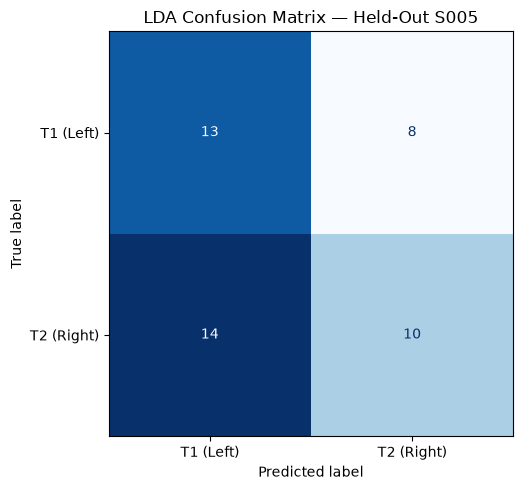

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["T1 (Left)", "T2 (Right)"])
fig, ax = plt.subplots(figsize=(6, 5))

disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("LDA Confusion Matrix — Held-Out S005")
plt.tight_layout()
plt.show()

### Confusion Matrix Results

The model correctly classified 23 of 45 motor imagery epochs.

Recall was higher for T1 (13/21) than for T2 (10/24), with 14 right-hand imagery epochs incorrectly classified as left-hand imagery.

The confusion matrix confirms limited and uneven classification performance on S005.

## Conclusion

LDA achieved the best exploratory performance during LOSO cross-validation on S001–S004, with **0.609 balanced accuracy** and **0.590 Macro-F1**.

When evaluated on S005, performance decreased to:

- **Accuracy:** 0.511
- **Balanced Accuracy:** 0.518
- **Macro-F1:** 0.509

Only 23 of 45 epochs were correctly classified, with lower recall for right-hand motor imagery (T2).

These results highlight limited cross-subject generalization. The small sample size and previous exploratory use of S005 prevent this experiment from serving as a fully independent final evaluation.

**Next step:** Investigate feature distributions, correlations, and subject-specific differences to identify potential limitations of the handcrafted EEG representation.